# Pitch SD decomposition

Pitch SD is highest when both participants' smiles are increased (SS). Here we compare SS with the three other conditions to see what in the pitch signal makes the difference, and when.

* Pitch frames : `talking == 1` and a valid `f0` (dry per-frame files, 5 ms). Recordings with less than 5 s of voiced speech are excluded, as in `R_scripts/audio_stats.R`.
* Semitones (st) are relative to each speaker's median f0 over all their interactions, so "p90" is the speaker's own high register.

# Imports

In [1]:
#Data handling, plots and statistics
import glob
import os
import re
import polars as pl
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
import statsmodels.formula.api as smf
from scipy import stats
import warnings
warnings.filterwarnings("ignore")

In [2]:
#Statistics used for every test
def lmm_stats(df, y):
    """
        Mixed model with random intercepts for participant and partner (ML).
        Returns the participant x other condition interaction (likelihood-ratio test, as in audio_stats.R)
        and SS minus each other condition.
    """
    df = df.dropna(subset=[y]).copy()
    df["y"] = df[y]

    #statsmodels has no crossed random effects : one single group (groups=np.ones) with two variance components,
    #a random intercept per participant and one per partner, equivalent to (1|user_id) + (1|other_id) in lme4
    vc = {"participant": "0 + C(user_id)", "other": "0 + C(other_id)"}

    #Additive model, and the full model written with one coefficient per condition, SS as the reference
    #(the full model is the same as participant_condition * other_condition, only the coefficients differ)
    m_add  = smf.mixedlm("y ~ participant_condition + other_condition", df, groups=np.ones(len(df)), vc_formula=vc).fit(reml=False)
    m_cond = smf.mixedlm("y ~ C(u_cond, Treatment('SS'))", df, groups=np.ones(len(df)), vc_formula=vc).fit(reml=False)

    #Likelihood-ratio test of the interaction : twice the log-likelihood difference, chi2 with 1 df
    chi2 = 2 * (m_cond.llf - m_add.llf)
    results = {"n": len(df), "chi2": chi2, "p": stats.chi2.sf(chi2, 1)}
    #Each coefficient is (condition - SS), so the sign is flipped to get SS - condition
    for cond in ["SU", "US", "UU"]:
        name = "C(u_cond, Treatment('SS'))[T." + cond + "]"
        results["SS-" + cond] = -m_cond.params[name]
        results["p SS-" + cond] = m_cond.pvalues[name]

    #Model-estimated mean of each condition : SS is the intercept, the others are intercept + their coefficient
    results["model SS"] = m_cond.params["Intercept"]
    for cond in ["SU", "US", "UU"]:
        results["model " + cond] = m_cond.params["Intercept"] + m_cond.params["C(u_cond, Treatment('SS'))[T." + cond + "]"]
    return results


def stats_table(df, measures):
    """lmm_stats for each measure"""
    stats_list = []
    for measure in measures:
        stats_list.append({"measure": measure, **lmm_stats(df, measure)})
    return pd.DataFrame(stats_list).round(4)

# Import data

In [3]:
#Conditions (server summary)
conditions_df = pd.read_csv("../data/audio_data/collapsed_pitch_from_server_v3.csv", index_col=0)

#Pitch frames of each recording
key = ["file", "sid", "dyad", "user_id", "other_id", "participant_condition", "other_condition", "u_cond"]

frames_list = []
for file in sorted(glob.glob("../data/audio_data/prolific_v3/*-dry.csv")):
    #Recording identifiers from the file name
    #Regex on the file name : session id after "-s-", dyad (p4p7) and user (p4) after "-u-"
    m = re.search(r"-s-(.+?)-n-\d+-(p\d+p\d+)-u-(p\d+)-c-\d+-dry\.csv$", os.path.basename(file))

    #Read the file and keep voiced frames
    df = pl.read_csv(file, columns=["", "f0", "talking"], schema_overrides={"": pl.Float64, "f0": pl.Float32, "talking": pl.Float32}).to_pandas()
    #The unnamed first column is the time in seconds
    df = df.rename({"": "time"}, axis=1)

    df = df.loc[df["talking"] == 1]

    df = df.dropna(subset=["f0"])

    df["file"] = os.path.basename(file)
    df["sid"] = m[1]
    df["dyad"] = m[2]
    df["user_id"] = m[1] + m[3]
    frames_list.append(df)

pitch_df = pd.concat(frames_list)

#Add conditions
pitch_df = pitch_df.merge(conditions_df, on=["sid", "dyad", "user_id"])
pitch_df["u_cond"] = pitch_df["participant_condition"] + pitch_df["other_condition"]

In [4]:
#Keep recordings with at least 5 s of voiced speech (1000 frames)
#transform("size") writes the number of frames of the recording on each of its rows
pitch_df["n_voiced"] = pitch_df.groupby("file")["f0"].transform("size")

pitch_df = pitch_df.loc[pitch_df["n_voiced"] >= 1000]

#Semitones re. the speaker's median (12 * log2 of the frequency ratio), and frames above the speaker's own p90
#(the median and p90 are computed over all the speaker's interactions)
pitch_df["st"] = 12 * np.log2(pitch_df["f0"] / pitch_df.groupby("user_id")["f0"].transform("median"))
pitch_df["high"] = pitch_df["st"] > pitch_df.groupby("user_id")["st"].transform(lambda x: x.quantile(0.9))

#Count recordings and participants
print("Number of recordings : " + str(pitch_df["file"].nunique()))
print("Number of participants : " + str(pitch_df["user_id"].nunique()))
pitch_df.groupby("u_cond")["file"].nunique()

Number of recordings : 174
Number of participants : 57


u_cond
SS    48
SU    42
US    38
UU    46
Name: file, dtype: int64

# Per-recording measures
`high_pct` : % of voiced speech above the speaker's p90. `high_runs_per_min` : number of runs above p90 (at least 30 ms) per minute of talking.

In [5]:
#Measures per recording
def count_runs(high, min_len=6):
    """
        Number of runs of consecutive high frames lasting at least min_len frames (6 frames = 30 ms).
    """
    #Start and end of each run : +1 where a run starts, -1 just after it ends
    edges = np.diff(np.r_[0, high.astype(int), 0])
    starts = np.where(edges == 1)[0]
    ends = np.where(edges == -1)[0]
    return np.sum(ends - starts >= min_len)


recordings_list = []
for keys, rec_df in pitch_df.groupby(key):
    recordings_list.append(dict(zip(key, keys)
                    , hz_mean = rec_df["f0"].mean()
                    , hz_std = rec_df["f0"].std()
                    , st_mean = rec_df["st"].mean()
                    , st_std = rec_df["st"].std()
                    , p10 = rec_df["st"].quantile(0.1)
                    , p50 = rec_df["st"].quantile(0.5)
                    , p90 = rec_df["st"].quantile(0.9)
                    , high_pct = 100 * rec_df["high"].mean()
                    #frames are 5 ms, so len * 0.005 / 60 = minutes of talking
                    , high_runs_per_min = count_runs(rec_df["high"].values) / (len(rec_df) * 0.005 / 60)
                    ))

recordings_df = pd.DataFrame(recordings_list)
recordings_df = recordings_df.merge(conditions_df[["sid", "dyad", "user_id", "f0_std"]], on=["sid", "dyad", "user_id"])

#Mean per condition
measures = ["f0_std", "hz_std", "hz_mean", "st_std", "st_mean", "p10", "p50", "p90", "high_pct", "high_runs_per_min"]
recordings_df.groupby("u_cond")[measures].mean().round(2)

,f0_std,hz_std,hz_mean,st_std,st_mean,p10,p50,p90,high_pct,high_runs_per_min
u_cond,,,,,,,,,,
SS,53.94,53.939999,207.720001,4.55,0.53,-4.39,0.43,5.88,11.68,54.17
SU,48.96,48.980000,200.960007,4.22,0.10,-4.11,-0.11,4.96,9.00,44.51
US,50.78,50.820000,200.059998,4.41,-0.01,-4.56,-0.14,5.11,9.05,45.74
UU,52.04,52.070000,203.500000,4.40,0.18,-4.63,-0.03,5.55,10.63,51.20


In [6]:
#Interaction and SS vs each condition, for each measure
stats_table(recordings_df, measures)

,measure,n,chi2,p,SS-SU,p SS-SU,SS-US,p SS-US,SS-UU,p SS-UU,model SS,model SU,model US,model UU
0,f0_std,174,8.3187,0.0039,4.0351,0.0025,2.6504,0.0539,1.0137,0.4331,53.8608,49.8258,51.2104,52.8471
1,hz_std,174,8.0968,0.0044,3.9850,0.0029,2.5884,0.0611,0.9515,0.4642,53.8309,49.8460,51.2426,52.8795
2,hz_mean,174,5.1497,0.0233,5.7525,0.0057,5.7066,0.0084,4.4126,0.0256,208.5501,202.7975,202.8434,204.1375
3,st_std,174,4.3801,0.0364,0.2646,0.0116,0.1047,0.3316,0.0475,0.6408,4.5217,4.2571,4.4170,4.4741
4,st_mean,174,5.8577,0.0155,0.4656,0.0077,0.5343,0.0031,0.3755,0.0264,0.5582,0.0926,0.0239,0.1826
5,p10,174,0.4243,0.5148,-0.0725,0.8350,0.1702,0.6383,0.4328,0.1966,-4.2817,-4.2092,-4.4519,-4.7145
6,p50,174,9.8080,0.0017,0.5780,0.0000,0.5467,0.0001,0.4861,0.0003,0.4569,-0.1212,-0.0898,-0.0292
7,p90,174,11.9754,0.0005,0.9071,0.0006,0.7729,0.0050,0.3089,0.2312,5.8965,4.9893,5.1236,5.5875
8,high_pct,174,12.9951,0.0003,2.7152,0.0003,2.4938,0.0015,0.9745,0.1857,11.7202,9.0050,9.2264,10.7457
9,high_runs_per_min,174,11.8440,0.0006,9.7407,0.0089,8.7045,0.0227,3.1550,0.3825,54.4802,44.7394,45.7757,51.3252


Pitch SD, mean pitch, p50, p90 and the high-register measures are higher in SS than in SU and US. The floor (p10) does not move.

# Pitch distributions
Density of each recording's pitch in cents relative to the speaker's median, averaged over recordings. Right : the upper tail on a log scale.

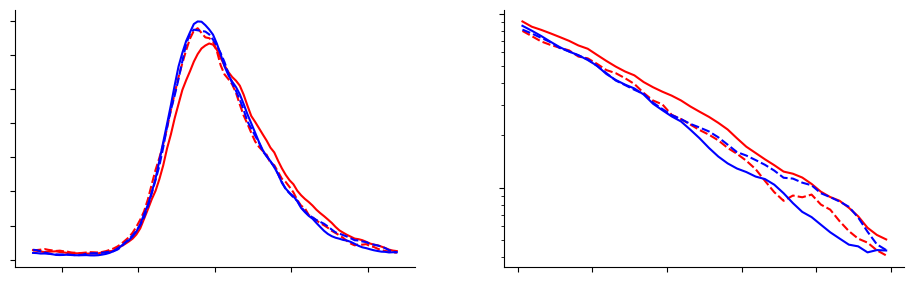

In [7]:
#Pitch histogram of each recording (cents re. speaker median), lightly smoothed
bins = np.arange(-1200, 1201, 25)

hist_list = []
for keys, rec_df in pitch_df.groupby(key):
    #Histogram normalised to a density (area = 1), so recordings with more speech do not weigh more
    density, edges = np.histogram(rec_df["st"] * 100, bins, density=True)

    df = pd.DataFrame({"cents": (edges[:-1] + edges[1:]) / 2, "density": density})
    #Light smoothing over 3 bins
    df["density"] = df["density"].rolling(3, center=True, min_periods=1).mean()
    for name, value in zip(key, keys):
        df[name] = value
    hist_list.append(df)

hist_df = pd.concat(hist_list)

#Same data twice : whole distribution and upper tail
df_analysis = hist_df.copy()
df_analysis["panel"] = "whole distribution"

df_tail = hist_df.loc[hist_df["cents"] > 200].copy()
df_tail["panel"] = "upper tail"

df_analysis = pd.concat([df_analysis, df_tail])

#Readable names for the figure (the column names become the legend titles)
df_analysis["participant_condition"] = df_analysis["participant_condition"].replace({"S": "increase", "U": "decrease"})
df_analysis["other_condition"] = df_analysis["other_condition"].replace({"S": "increase", "U": "decrease"})
df_analysis = df_analysis.rename({"participant_condition": "participant condition", "other_condition": "other condition"}, axis=1)

#Plot
g = sns.relplot(x="cents", y="density"
            , aspect=1.2
            , height=3.5
            , hue="other condition"
            , style="participant condition"
            , col="panel"
            , data= df_analysis
            , kind="line"
            , ci=None
            , hue_order = ["increase", "decrease"]
            , style_order = ["increase", "decrease"]
            , palette= ["red", "blue"]
            , facet_kws={"sharex": False, "sharey": False}
            )
g.axes[0, 1].set_yscale("log")

#Legend on top of the plot, on one line, instead of on the right
sns.move_legend(g, "lower center", bbox_to_anchor=(0.5, 1.03), ncol=6, frameon=False, columnspacing=0.8, handlelength=1.6, handletextpad=0.4, borderpad=0)
g.figure.subplots_adjust(right=0.97)

#Save with and without labels
plt.savefig("plots/pitch_std_decomposition/pitch_distributions_legend.pdf", bbox_inches='tight')
g._legend.remove()
g.set(xticklabels=[], yticklabels=[], title='',xlabel=None, ylabel=None)
plt.savefig("plots/pitch_std_decomposition/pitch_distributions.pdf", bbox_inches='tight')

# Quantile profile
Each percentile of the recording's pitch distribution (st re. the speaker's median), mean ± 1 SEM across recordings.

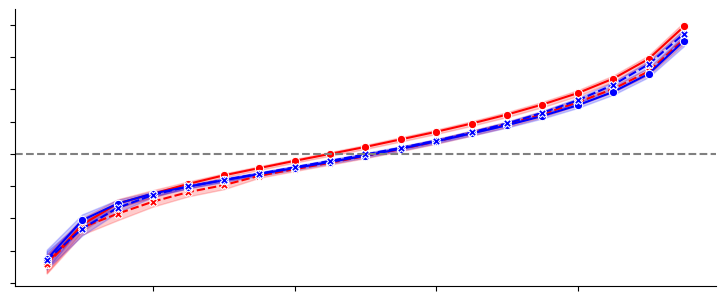

In [8]:
#Percentiles of each recording
quantile_df = pitch_df.groupby(key)["st"].quantile(np.arange(0.05, 0.951, 0.05).round(2)).reset_index()
#groupby().quantile() puts the percentile in an unnamed column (level_8, after the 8 grouping columns)
quantile_df = quantile_df.rename({"level_8": "percentile"}, axis=1)
quantile_df["percentile"] = (quantile_df["percentile"] * 100).round().astype(int)

#Readable names for the figure (the column names become the legend titles)
df_analysis = quantile_df.copy()
df_analysis["participant_condition"] = df_analysis["participant_condition"].replace({"S": "increase", "U": "decrease"})
df_analysis["other_condition"] = df_analysis["other_condition"].replace({"S": "increase", "U": "decrease"})
df_analysis = df_analysis.rename({"participant_condition": "participant condition", "other_condition": "other condition"}, axis=1)

#Plot
g = sns.relplot(x="percentile", y="st"
            , aspect=1.7
            , height=3.5
            , hue="other condition"
            , style="participant condition"
            , data= df_analysis
            , kind="line"
            , errorbar="se"
            , markers=True
            , dashes=True
            , hue_order = ["increase", "decrease"]
            , style_order = ["increase", "decrease"]
            , palette= ["red", "blue"]
            )
g.refline(y=0, color="grey")

#Axis labels
g.set_axis_labels("percentile of the recording's pitch distribution", "pitch (semitones re. speaker median)")

#Legend on top of the plot, on one line, instead of on the right
sns.move_legend(g, "lower center", bbox_to_anchor=(0.5, 0.97), ncol=6, frameon=False, columnspacing=0.8, handlelength=1.6, handletextpad=0.4, borderpad=0)
g.figure.subplots_adjust(right=0.97)

#Save with and without labels
plt.savefig("plots/pitch_std_decomposition/quantile_profile_legend.pdf", bbox_inches='tight')
g._legend.remove()
g.set(xticklabels=[], yticklabels=[], title='',xlabel=None, ylabel=None)
plt.savefig("plots/pitch_std_decomposition/quantile_profile.pdf", bbox_inches='tight')

# Time course of the high register
% of voiced speech above the speaker's p90 in a 25 s window sliding by 5 s (mean ± 1 SEM across recordings). Windows need at least 1 s of pitch.

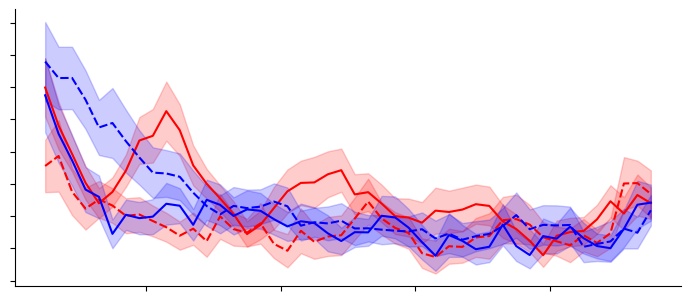

In [9]:
#Percentage of high frames in each 25 s window, sliding by 5 s
window_list = []
for start in range(0, 226, 5):
    df = pitch_df.loc[(pitch_df["time"] >= start) & (pitch_df["time"] < start + 25)]
    #Share of high frames (mean of True/False) and number of pitch frames in the window
    df = df.groupby(key)["high"].agg(["mean", "size"]).reset_index()

    #At least 1 s of pitch (200 frames of 5 ms)
    df = df.loc[df["size"] >= 200]

    df["high_pct"] = 100 * df["mean"]
    df["start"] = start
    df["time"] = start + 12.5
    window_list.append(df)

window_df = pd.concat(window_list)

#Readable names for the figure (the column names become the legend titles)
df_analysis = window_df.copy()
df_analysis["participant_condition"] = df_analysis["participant_condition"].replace({"S": "increase", "U": "decrease"})
df_analysis["other_condition"] = df_analysis["other_condition"].replace({"S": "increase", "U": "decrease"})
df_analysis = df_analysis.rename({"participant_condition": "participant condition", "other_condition": "other condition"}, axis=1)

#Plot
g = sns.relplot(x="time", y="high_pct"
            , aspect=1.7
            , height=3.5
            , hue="other condition"
            , style="participant condition"
            , data= df_analysis
            , kind="line"
            , errorbar="se"
            , hue_order = ["increase", "decrease"]
            , style_order = ["increase", "decrease"]
            , palette= ["red", "blue"]
            )

#Axis labels
g.set_axis_labels("time in the interaction (s, centre of the 25 s window)", "voiced speech above the\nspeaker's 90th percentile (%)")

#Legend on top of the plot, on one line, instead of on the right
sns.move_legend(g, "lower center", bbox_to_anchor=(0.5, 0.97), ncol=6, frameon=False, columnspacing=0.8, handlelength=1.6, handletextpad=0.4, borderpad=0)
g.figure.subplots_adjust(right=0.97)

#Save with and without labels
plt.savefig("plots/pitch_std_decomposition/time_course_high_register_legend.pdf", bbox_inches='tight')
g._legend.remove()
g.set(xticklabels=[], yticklabels=[], title='',xlabel=None, ylabel=None)
plt.savefig("plots/pitch_std_decomposition/time_course_high_register.pdf", bbox_inches='tight')

Neighbouring windows share 20 s of data, so the tests use non-overlapping 25 s bins.

In [10]:
#Tests in non-overlapping 25 s bins
stats_list = []
for start in range(0, 226, 25):
    df_analysis = window_df.loc[window_df["start"] == start]
    stats_list.append({"bin": str(start) + "-" + str(start + 25) + " s", **lmm_stats(df_analysis, "high_pct")})

pd.DataFrame(stats_list).round(4)

,bin,n,chi2,p,SS-SU,p SS-SU,SS-US,p SS-US,SS-UU,p SS-UU,model SS,model SU,model US,model UU
0,0-25 s,141,3.3730,0.0663,0.5075,0.8776,5.7244,0.0863,-2.2976,0.4944,19.8908,19.3833,14.1665,22.1885
1,25-50 s,170,9.0433,0.0026,3.2881,0.1564,1.0639,0.6537,-5.3482,0.0195,11.8945,8.6065,10.8306,17.2428
2,50-75 s,169,10.7146,0.0011,5.8401,0.0091,8.2984,0.0003,3.6767,0.0898,16.7372,10.8970,8.4387,13.0605
3,75-100 s,164,0.0049,0.9439,-1.9998,0.2456,-0.0554,0.9754,-2.1661,0.2036,8.5295,10.5293,8.5850,10.6956
4,100-125 s,162,3.9006,0.0483,3.0672,0.0908,4.8312,0.0111,2.4985,0.1647,12.4781,9.4109,7.6469,9.9796
5,125-150 s,166,-0.0209,1.0000,1.0298,0.5824,1.1334,0.5515,2.0623,0.2491,10.9838,9.9540,9.8505,8.9215
6,150-175 s,159,0.9182,0.3380,1.9432,0.3515,2.6040,0.2443,1.5487,0.4534,10.3646,8.4214,7.7605,8.8158
7,175-200 s,160,0.3108,0.5772,1.4071,0.4571,-0.7494,0.7102,-0.9026,0.6341,9.1414,7.7343,9.8908,10.0440
8,200-225 s,158,-0.0370,1.0000,0.4939,0.7492,0.2773,0.8657,1.1866,0.4344,8.8672,8.3732,8.5899,7.6806
9,225-250 s,155,0.1699,0.6802,-0.0434,0.9806,-0.8269,0.6488,0.2140,0.9031,11.0076,11.0510,11.8346,10.7936


The difference is in the opening of the conversation : the interaction is significant at 25–50 s and 50–75 s (0–25 s : p = .066), and SS − SU / SS − US peak at 50–75 s (+5.8 / +8.3 points). After 75 s the four conditions mostly overlap (100–125 s : p = .048). (In the 125–150 s and 200–225 s bins the model fit did not converge, hence χ² < 0.)

# First and second half
Measures reported in the Supplementary Information; the statistics are in `R_scripts/pitch_halves_stats.R`, on the table written here. Each recording is split into its first (0–125 s) and second (125–250 s) half, and the measures are recomputed in each half (halves with at least 2.5 s of voiced speech).

In [11]:
#Split each recording into two halves
pitch_df["half"] = np.where(pitch_df["time"] < 125, "first", "second")

#Measures per recording and half (the speaker's median and p90 still come from all their interactions)
half_list = []
for keys, rec_df in pitch_df.groupby(key + ["half"]):
    half_list.append(dict(zip(key + ["half"], keys)
                    , n_voiced = len(rec_df)
                    , f0_std = rec_df["f0"].std()
                    , high_pct = 100 * rec_df["high"].mean()
                    , p90 = rec_df["st"].quantile(0.9)
                    ))

half_df = pd.DataFrame(half_list)

#Keep halves with at least 2.5 s of voiced speech (500 frames of 5 ms)
half_df = half_df.loc[half_df["n_voiced"] >= 500]

print("Number of recordings per half : " + str(half_df.groupby("half").size().to_dict()))

#Table for R_scripts/pitch_halves_stats.R
half_df.to_csv("../data/audio_data/pitch_halves_v3.csv", index=False)

Number of recordings per half : {'first': 174, 'second': 173}


The effect is in the first half (`R_scripts/pitch_halves_stats.R`, 174 / 173 recordings). Pitch SD : interaction χ²(1) = 16.17, p < .001 in the first half (SS − SU = +5.4 Hz, SS − US = +4.9 Hz), χ²(1) = 0.20, p = .65 in the second; half × participant × other condition χ²(1) = 8.51, p = .0035. In the first half, SS spends 13.3 % of its voiced speech above the speaker's 90th percentile (model estimate) against 9.8 % in SU and 9.6 % in US (interaction χ²(1) = 18.82, p < .001; half × participant × other χ²(1) = 10.19, p = .0014), and its 90th percentile is about 1.1 semitones higher than SU and US (interaction χ²(1) = 16.72, p < .001; half × participant × other χ²(1) = 5.79, p = .016).

# Conclusions
* SS speaks in a raised, more animated register. Compared with SU and US, the lowest pitches (p10) do not change, the middle rises by about 0.55 st (p50) and the top rises most (p90 +0.8 to +0.9 st). This upward stretch is what makes the SD larger.
* SS goes more often into the high register : about 12 % of SS pitch frames are above the speaker's p90, against 9 % in SU and US, with 9 to 10 more high runs per minute of talking.
* UU is in between : SS − UU goes the same way but is smaller (p90 +0.3 st, n.s.; SD n.s.).
* The difference is in the first ~75 s of the conversation, and in the first half (0–125 s) only.